# 📊 Dataset Information

**Note:** The dataset for this project is **not included in this repository** to keep the repository lightweight.  

You can download the dataset from **Kaggle** using the link below:  

[Download The Retail Store Sales Dataset](https://www.kaggle.com/datasets/hassanjameelahmed/store-sales)  

Please make sure to place the downloaded CSV file in the same directory as this notebook before running any code.

# Importing

## Import Library

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

## Import CSV And convert to DataFrame

In [2]:
df = pd.read_csv('store_sales.csv')

# Preprocessing

## Frist five row

In [3]:
df.head()

,CustomerID,Age,Gender,Category,ItemPurchased,Amount,Season,PaymentMethod,ItemRating,DiscountApplied(%),PreviousPurchases
0,1,58,Female,Accessories,Handbag,115.50,Autumn,Card,3.5,18,4
1,2,40,Male,Mens Clothing,Shirt,103.43,Spring,Card,4.1,13,4
2,3,66,Female,Sports,Football,35.45,Spring,Card,3.3,11,3
3,4,39,Female,Accessories,Handbag,153.31,Spring,Card,4.4,13,4
4,5,23,Female,Home,Curtains,151.43,Winter,Card,4.1,20,10


## last Five row

In [4]:
df.tail()

,CustomerID,Age,Gender,Category,ItemPurchased,Amount,Season,PaymentMethod,ItemRating,DiscountApplied(%),PreviousPurchases
4995,4996,44,Female,Accessories,Sunglasses,172.64,Winter,Card,3.6,20,5
4996,4997,59,Male,Groceries,Beverages,54.00,Spring,Cash on Delivery,3.8,14,2
4997,4998,41,Female,Accessories,Handbag,159.33,Autumn,Card,4.3,26,8
4998,4999,63,Female,Womens Clothing,Skirt,173.82,Autumn,Card,4.8,26,8
4999,5000,41,Female,Footwear,Sandals,55.39,Autumn,Cash on Delivery,4.1,19,7


## Shape of our dataset

In [5]:
df.shape

(5000, 11)

## List out all columns

In [6]:
df.columns

Index(['CustomerID', 'Age', 'Gender', 'Category', 'ItemPurchased', 'Amount',
       'Season', 'PaymentMethod', 'ItemRating', 'DiscountApplied(%)',
       'PreviousPurchases'],
      dtype='object')

## Datatype of each columns

In [7]:
df.dtypes

CustomerID              int64
Age                     int64
Gender                 object
Category               object
ItemPurchased          object
Amount                float64
Season                 object
PaymentMethod          object
ItemRating            float64
DiscountApplied(%)      int64
PreviousPurchases       int64
dtype: object

## Information of all Columns

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 11 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   CustomerID          5000 non-null   int64  
 1   Age                 5000 non-null   int64  
 2   Gender              5000 non-null   object 
 3   Category            5000 non-null   object 
 4   ItemPurchased       5000 non-null   object 
 5   Amount              5000 non-null   float64
 6   Season              5000 non-null   object 
 7   PaymentMethod       5000 non-null   object 
 8   ItemRating          5000 non-null   float64
 9   DiscountApplied(%)  5000 non-null   int64  
 10  PreviousPurchases   5000 non-null   int64  
dtypes: float64(2), int64(4), object(5)
memory usage: 429.8+ KB


## Check Null Value

In [9]:
df.isnull().sum()

CustomerID            0
Age                   0
Gender                0
Category              0
ItemPurchased         0
Amount                0
Season                0
PaymentMethod         0
ItemRating            0
DiscountApplied(%)    0
PreviousPurchases     0
dtype: int64

## Check Dupicate Value

In [10]:
df.duplicated().sum()

np.int64(0)

## Summary

In [11]:
df.describe()

,CustomerID,Age,Amount,ItemRating,DiscountApplied(%),PreviousPurchases
count,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000
mean,2500.500000,45.224800,285.090522,3.784160,14.983600,5.008800
std,1443.520003,14.564995,551.454382,0.681796,5.988063,2.194285
min,1.000000,20.000000,5.080000,1.100000,0.000000,0.000000
25%,1250.750000,33.000000,70.547500,3.300000,11.000000,3.000000
50%,2500.500000,45.000000,122.485000,3.800000,15.000000,5.000000
75%,3750.250000,58.000000,184.535000,4.300000,19.000000,6.000000
max,5000.000000,70.000000,2997.940000,5.000000,36.000000,13.000000


# EDA

In [12]:
def show_fig():
    plt.tight_layout()
    plt.show()

plot_no = 1

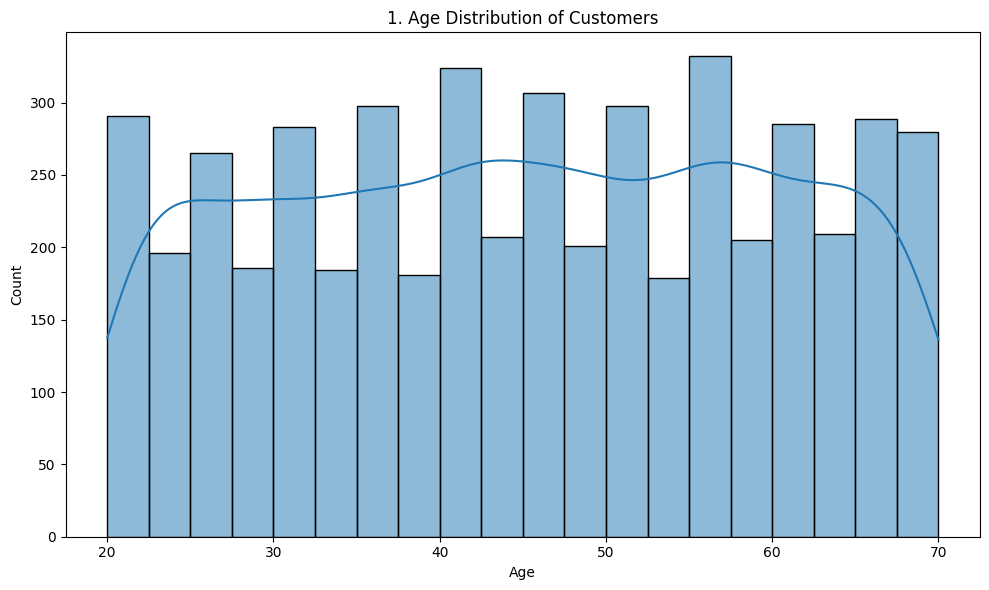

In [13]:
fig = plt.figure(figsize=(10,6))
sns.histplot(data=df, x='Age', kde=True, bins=20)
plt.title(f'{plot_no}. Age Distribution of Customers')
show_fig()
plot_no += 1

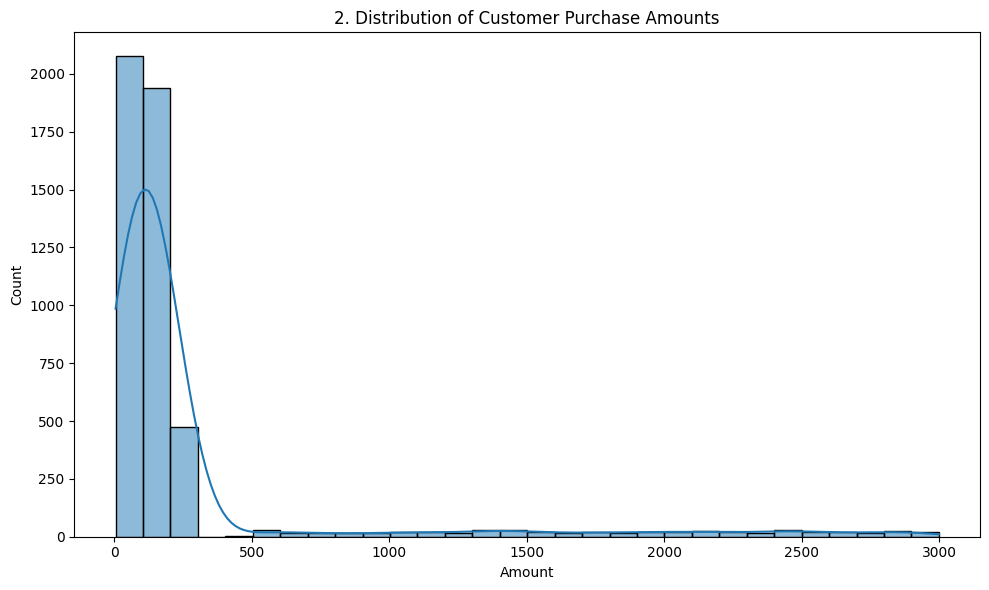

In [14]:
fig = plt.figure(figsize=(10,6))
sns.histplot(data=df, x='Amount', kde=True, bins=30)
plt.title(f'{plot_no}. Distribution of Customer Purchase Amounts')
show_fig()
plot_no += 1

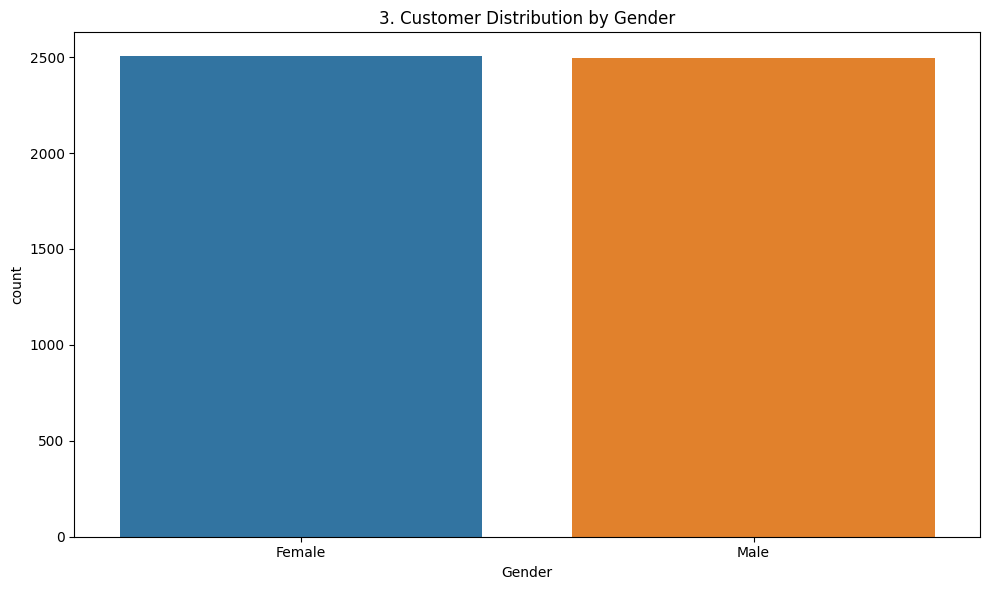

In [15]:
fig = plt.figure(figsize=(10,6))
sns.countplot(data=df, x='Gender', hue='Gender')
plt.title(f'{plot_no}. Customer Distribution by Gender')
show_fig()
plot_no += 1

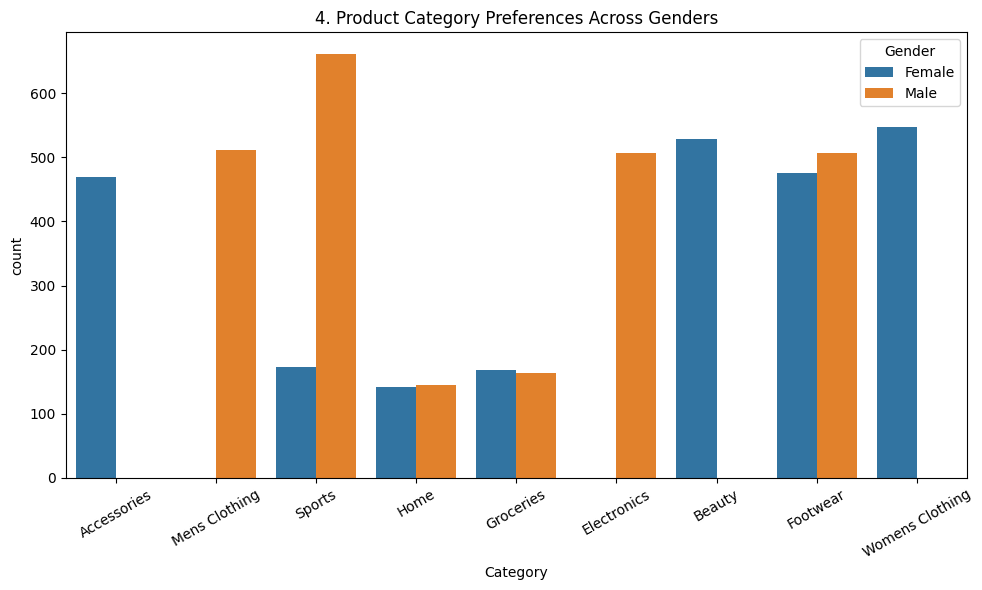

In [16]:
fig = plt.figure(figsize=(10,6))
sns.countplot(data=df, x='Category', hue='Gender')
plt.xticks(rotation=30)
plt.title(f'{plot_no}. Product Category Preferences Across Genders')
show_fig()
plot_no += 1

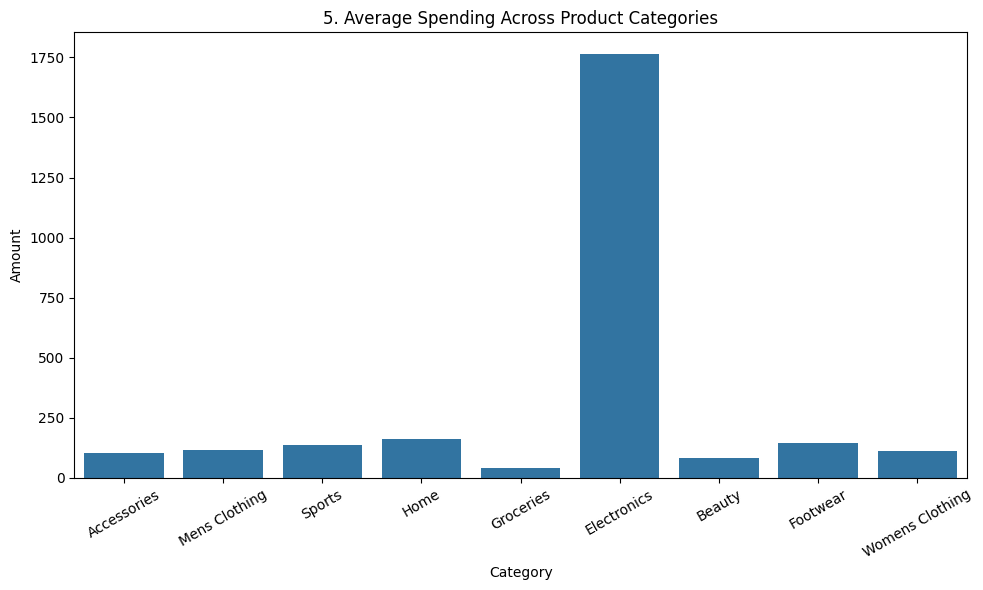

In [17]:
fig = plt.figure(figsize=(10,6))
sns.barplot(data=df, x='Category', y='Amount', estimator='mean', errorbar=None)
plt.xticks(rotation=30)
plt.title(f'{plot_no}. Average Spending Across Product Categories')
show_fig()
plot_no += 1

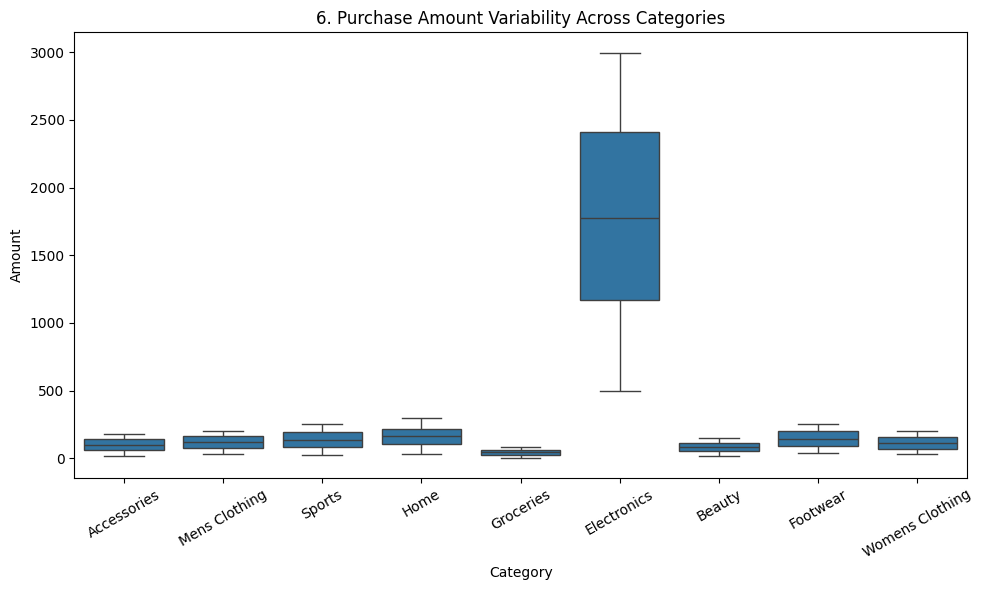

In [18]:
fig = plt.figure(figsize=(10,6))
sns.boxplot(data=df, x='Category', y='Amount')
plt.xticks(rotation=30)
plt.title(f'{plot_no}. Purchase Amount Variability Across Categories')
show_fig()
plot_no += 1

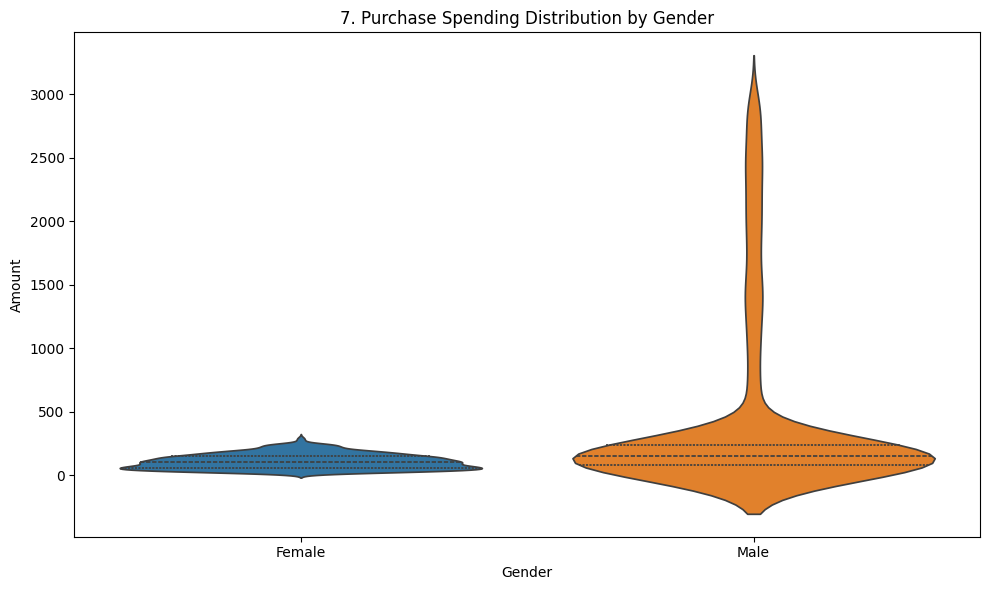

In [19]:
fig = plt.figure(figsize=(10,6))
sns.violinplot(data=df, x='Gender', y='Amount', hue='Gender', inner='quartile')
plt.title(f'{plot_no}. Purchase Spending Distribution by Gender')
show_fig()
plot_no += 1

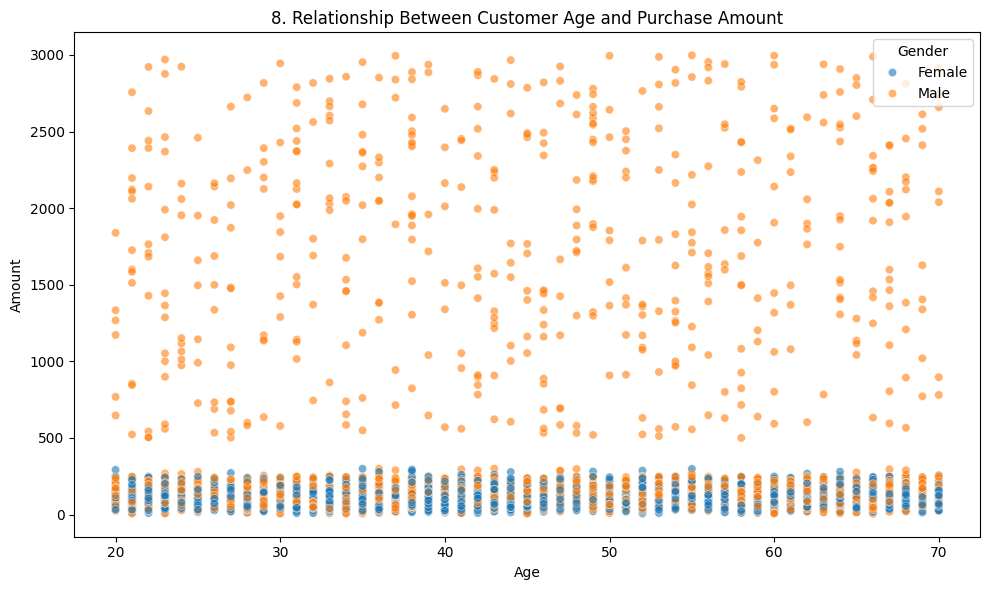

In [20]:
fig = plt.figure(figsize=(10,6))
sns.scatterplot(data=df, x='Age', y='Amount', hue='Gender', alpha=0.6)
plt.title(f'{plot_no}. Relationship Between Customer Age and Purchase Amount')
show_fig()
plot_no += 1

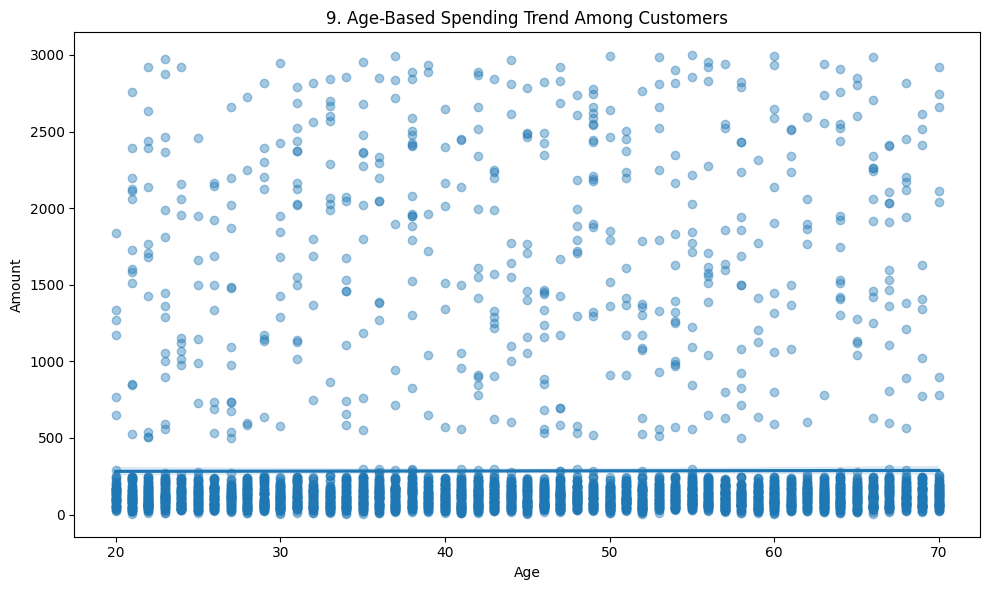

In [21]:
fig = plt.figure(figsize=(10,6))
sns.regplot(data=df, x='Age', y='Amount', scatter_kws={'alpha':0.4})
plt.title(f'{plot_no}. Age-Based Spending Trend Among Customers')
show_fig()
plot_no += 1

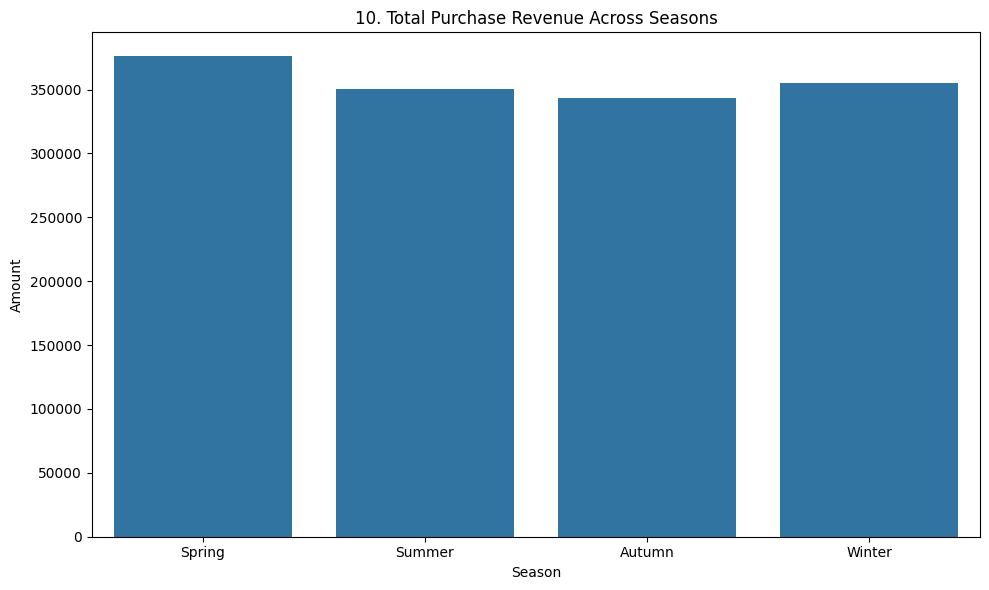

In [22]:
fig = plt.figure(figsize=(10,6))
sns.barplot(data=df, x='Season', y='Amount', estimator='sum', errorbar=None, order=['Spring','Summer','Autumn','Winter'])
plt.title(f'{plot_no}. Total Purchase Revenue Across Seasons')
show_fig()
plot_no += 1

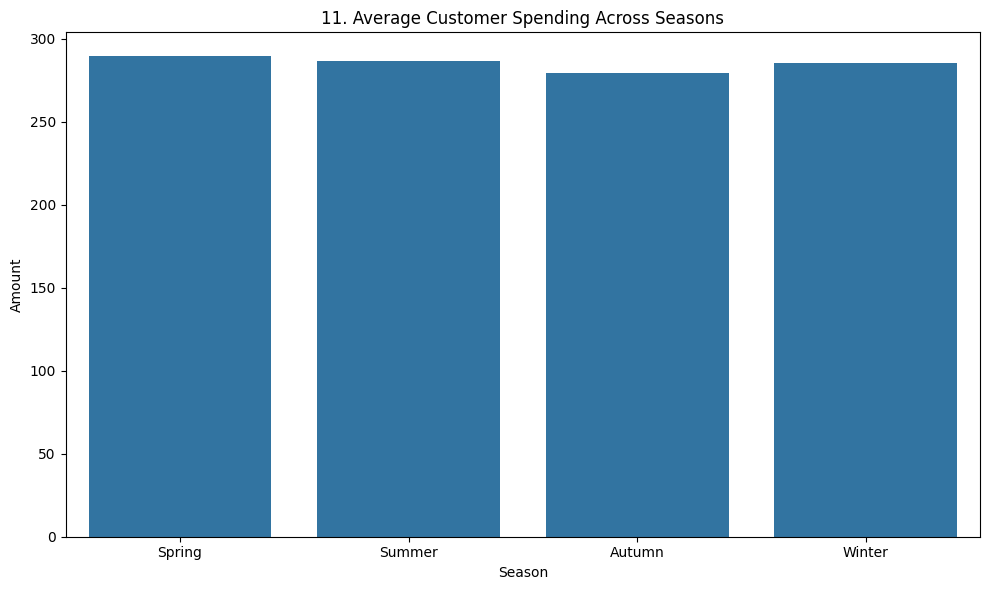

In [23]:
fig = plt.figure(figsize=(10,6))
sns.barplot(data=df, x='Season', y='Amount', estimator='mean', errorbar=None, order=['Spring','Summer','Autumn','Winter'])
plt.title(f'{plot_no}. Average Customer Spending Across Seasons')
show_fig()
plot_no += 1

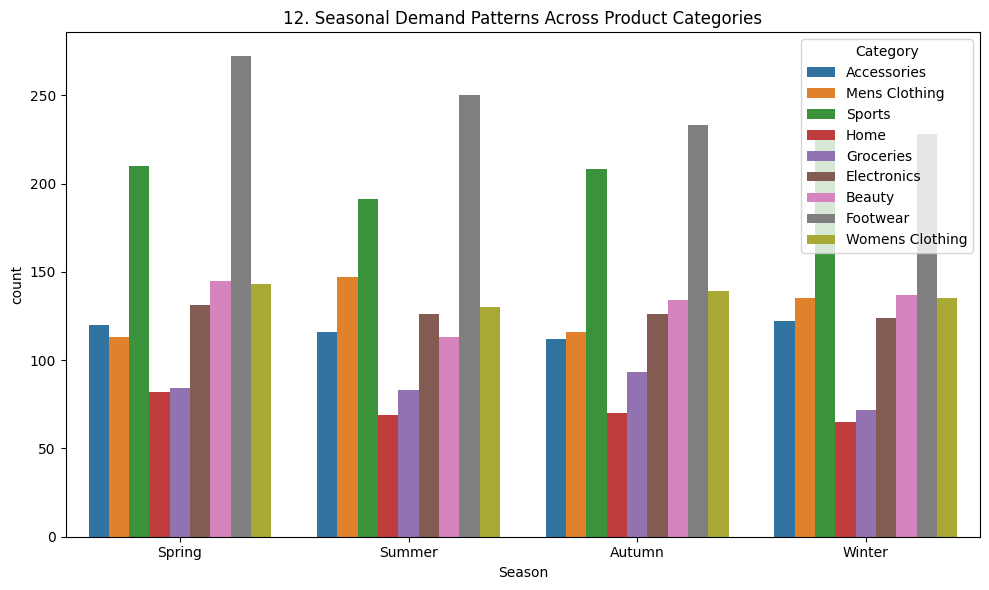

In [24]:
fig = plt.figure(figsize=(10,6))
sns.countplot(data=df, x='Season', hue='Category', order=['Spring','Summer','Autumn','Winter'])
plt.title(f'{plot_no}. Seasonal Demand Patterns Across Product Categories')
show_fig()
plot_no += 1

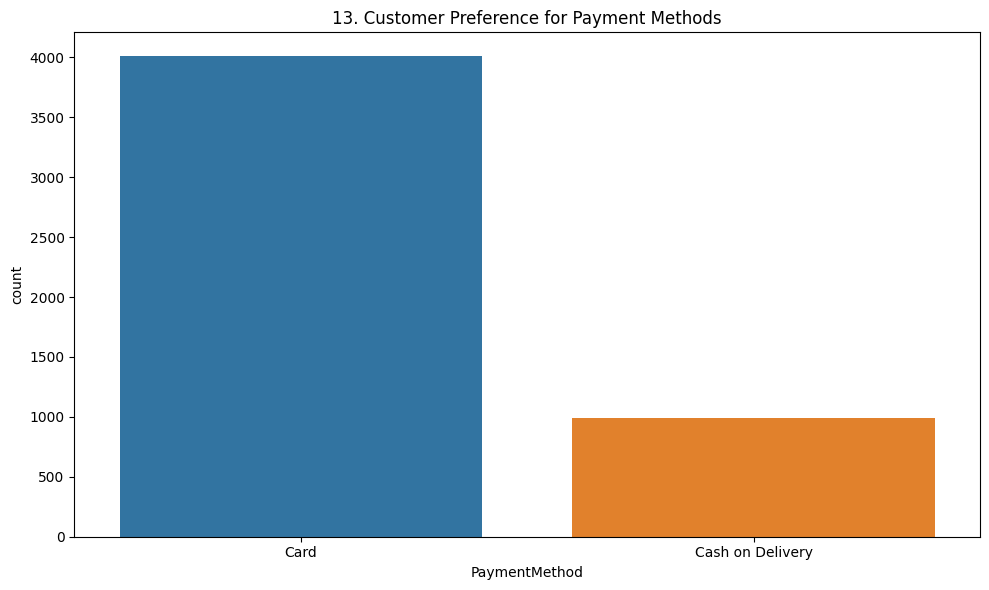

In [25]:
fig = plt.figure(figsize=(10,6))
sns.countplot(data=df, x='PaymentMethod', hue='PaymentMethod')
plt.title(f'{plot_no}. Customer Preference for Payment Methods')
show_fig()
plot_no += 1

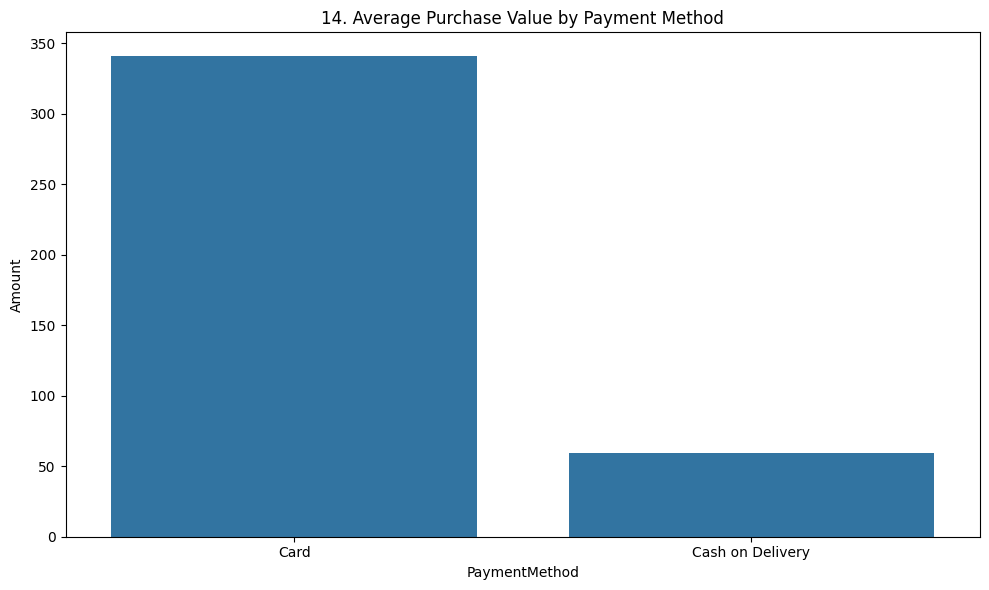

In [26]:
fig = plt.figure(figsize=(10,6))
sns.barplot(data=df, x='PaymentMethod', y='Amount', estimator='mean', errorbar=None)
plt.title(f'{plot_no}. Average Purchase Value by Payment Method')
show_fig()
plot_no += 1

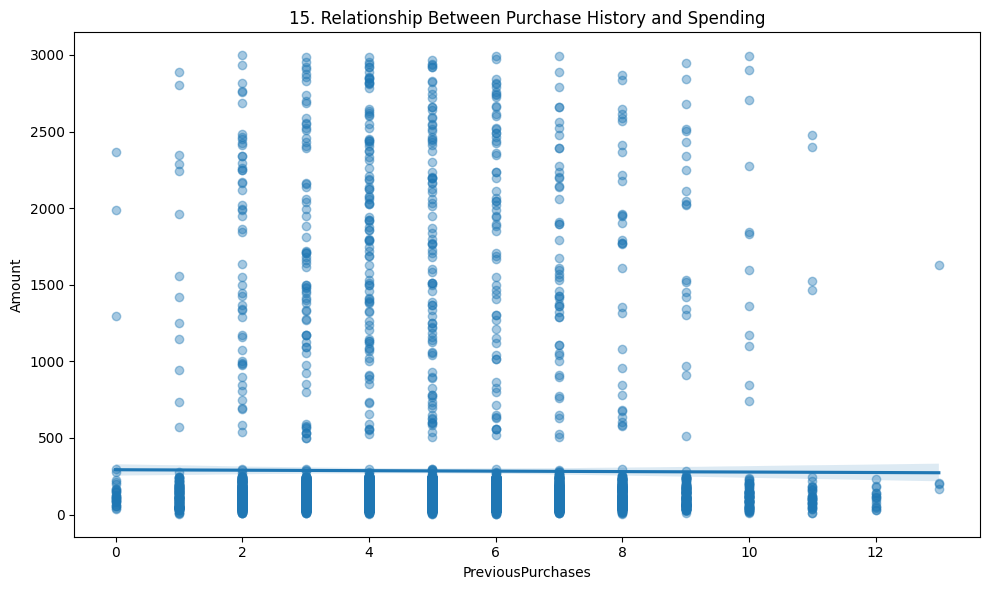

In [27]:
fig = plt.figure(figsize=(10,6))
sns.regplot(data=df, x='PreviousPurchases', y='Amount', scatter_kws={'alpha':0.4})
plt.title(f'{plot_no}. Relationship Between Purchase History and Spending')
show_fig()
plot_no += 1

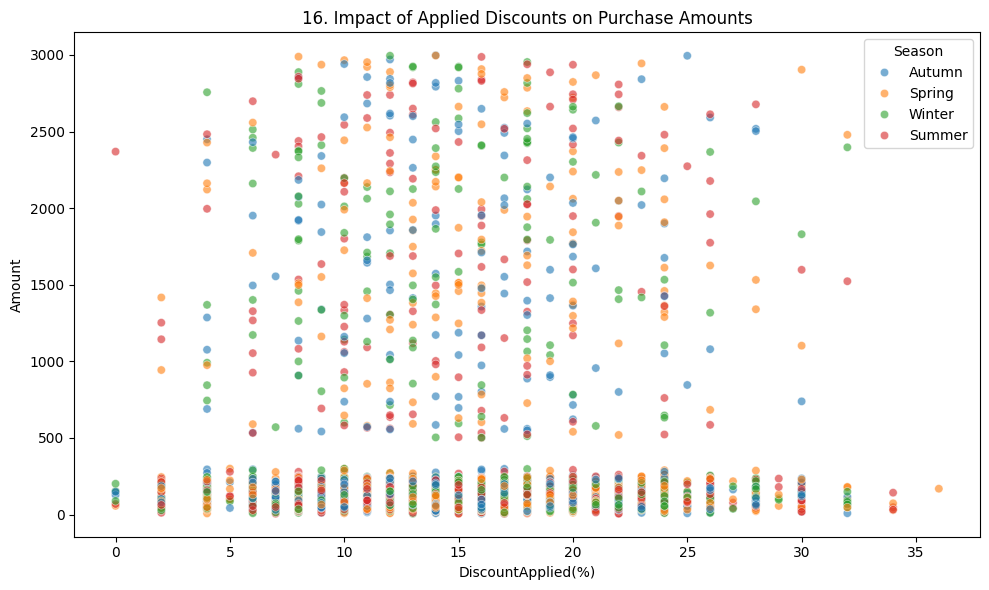

In [28]:
fig = plt.figure(figsize=(10,6))
sns.scatterplot(data=df, x='DiscountApplied(%)', y='Amount', hue='Season', alpha=0.6)
plt.title(f'{plot_no}. Impact of Applied Discounts on Purchase Amounts')
show_fig()
plot_no += 1

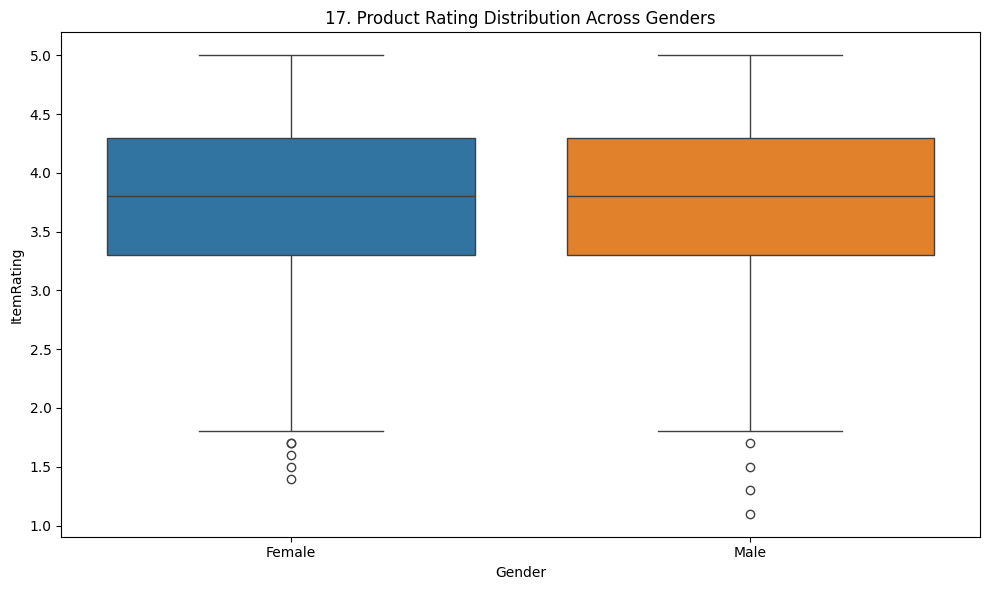

In [29]:
fig = plt.figure(figsize=(10,6))
sns.boxplot(data=df, x='Gender', y='ItemRating', hue='Gender')
plt.title(f'{plot_no}. Product Rating Distribution Across Genders')
show_fig()
plot_no += 1

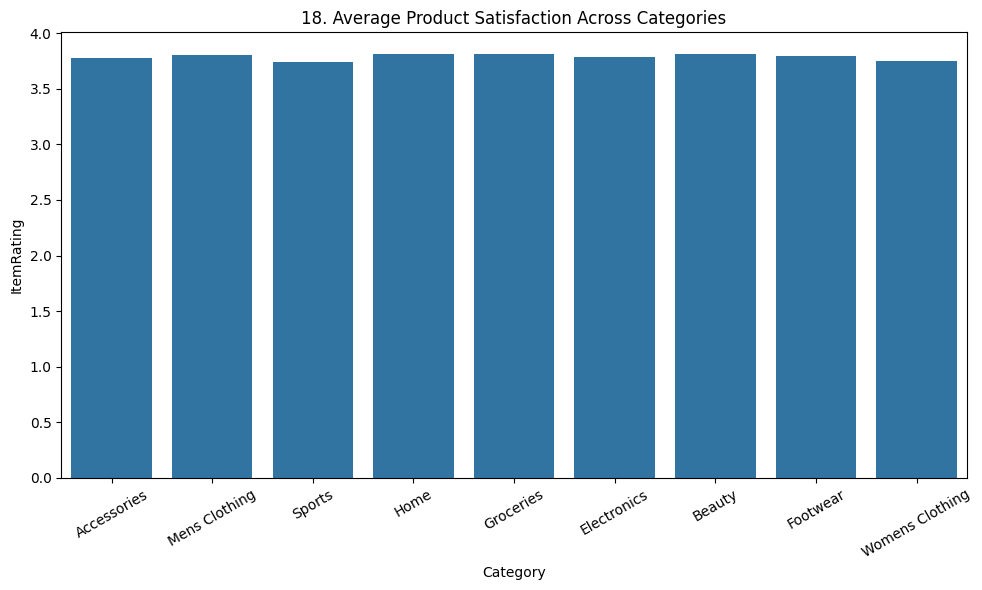

In [30]:
fig = plt.figure(figsize=(10,6))
sns.barplot(data=df, x='Category', y='ItemRating', estimator='mean', errorbar=None)
plt.xticks(rotation=30)
plt.title(f'{plot_no}. Average Product Satisfaction Across Categories')
show_fig()
plot_no += 1

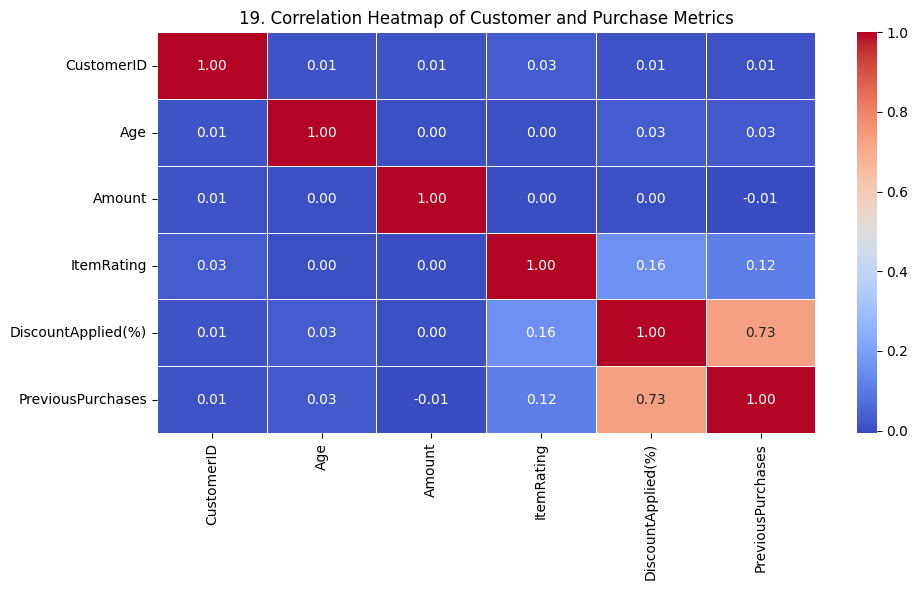

In [31]:
corr = df.select_dtypes(include='number').corr()

fig = plt.figure(figsize=(10,6))
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title(f'{plot_no}. Correlation Heatmap of Customer and Purchase Metrics')
show_fig()
plot_no += 1

# Model Training

## Prepare features and target

In [32]:
X = df.drop(columns=['Amount', 'CustomerID', 'ItemPurchased'])
y = df['Amount']

## Identify numerical and categorical columns

In [33]:
num_cols = X.select_dtypes(include=np.number).columns
cat_cols = X.select_dtypes(include='object').columns

## Create preprocessing pipeline

In [34]:
preprocessor = ColumnTransformer([
    ('num', Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler())
    ]), num_cols),
    ('cat', Pipeline([
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('encoder', OneHotEncoder(handle_unknown='ignore'))
    ]), cat_cols)
])

## Split dataset into training and testing data

In [35]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

## Create and train regression model

In [36]:
model = Pipeline([
    ('preprocessor', preprocessor),
    ('regressor', HistGradientBoostingRegressor(
        max_iter=200,
        learning_rate=0.05,
        max_leaf_nodes=15,
        l2_regularization=1.0,
        random_state=42
    ))
])

model.fit(X_train, y_train)

,steps,"[('preprocessor', ...), ('regressor', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


## Generate predictions

In [37]:
y_pred = model.predict(X_test)

## Evaluate model performance

In [38]:
print("Training R2 Score:", round(model.score(X_train, y_train), 4))
print("Testing R2 Score:", round(r2_score(y_test, y_pred), 4))
print("Mean Absolute Error:", round(mean_absolute_error(y_test, y_pred), 2))
print("Root Mean Squared Error:", round(np.sqrt(mean_squared_error(y_test, y_pred)), 2))

Training R2 Score: 0.8979
Testing R2 Score: 0.7895
Mean Absolute Error: 106.18
Root Mean Squared Error: 260.32


## Plot actual vs predicted values

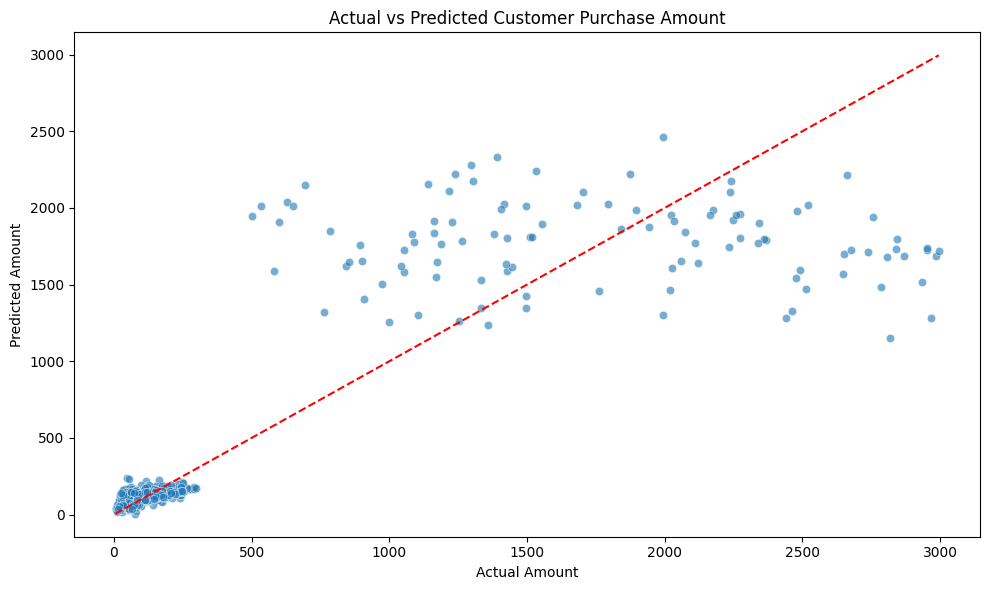

In [39]:
fig = plt.figure(figsize=(10,6))
sns.scatterplot(x=y_test, y=y_pred, alpha=0.6)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--')
plt.xlabel('Actual Amount')
plt.ylabel('Predicted Amount')
plt.title('Actual vs Predicted Customer Purchase Amount')
show_fig()
